In [13]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [14]:
import pandas as pd
import requests

country = "EGY"

indicators = {
    "GDP_Growth": "NY.GDP.MKTP.KD.ZG",
    "Inflation": "FP.CPI.TOTL.ZG",
    "Unemployment": "SL.UEM.TOTL.ZS",
}

data = {}

for name, code in indicators.items():
    url = f"https://api.worldbank.org/v2/country/{country}/indicator/{code}"

    params = {"date": "2014:2024", "format": "json", "per_page": 100}

    response = requests.get(url, params=params)
    result = response.json()

    # التحقق من وجود البيانات في العنصر الثاني من القائمة
    if len(result) > 1 and result[1] is not None:
        records = result[1]
        data[name] = {item["date"]: item["value"] for item in records}

df = pd.DataFrame(data)
df.index = df.index.astype(int)
df.index.name = "Year"
df = df.sort_index()

print("Data collected successfully!")
display(df)

Data collected successfully!


,GDP_Growth,Inflation,Unemployment
Year,,,
2014,2.915912,10.070215,13.105
2015,4.372019,10.370490,13.052
2016,4.346643,13.813606,12.450
2017,4.181221,29.506608,11.767
2018,5.331109,14.401466,9.855
2019,5.552093,9.152800,7.851
2020,3.550165,5.044933,7.974
2021,3.290646,5.214049,7.441
2022,6.587846,13.895661,6.546


In [15]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 11 entries, 2014 to 2024
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   GDP_Growth    11 non-null     float64
 1   Inflation     11 non-null     float64
 2   Unemployment  11 non-null     float64
dtypes: float64(3)
memory usage: 352.0 bytes

Statistical Summary:


,GDP_Growth,Inflation,Unemployment
count,11.000000,11.000000,11.000000
mean,4.207918,15.784109,9.419182
std,1.232662,10.070751,2.688246
min,2.399169,5.044933,6.546000
25%,3.420405,9.611508,7.129000
50%,4.181221,13.813606,7.974000
75%,4.851564,21.336028,12.108500
max,6.587846,33.884776,13.105000



First 5 Rows:


,GDP_Growth,Inflation,Unemployment
Year,,,
2014,2.915912,10.070215,13.105
2015,4.372019,10.370490,13.052
2016,4.346643,13.813606,12.450
2017,4.181221,29.506608,11.767
2018,5.331109,14.401466,9.855


In [16]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

df = df.drop_duplicates()

df = df.dropna()

print("\nCleaned Dataset:")
display(df)

print("\nFinal Dataset Shape:")
print(df.shape)

Missing Values:
GDP_Growth      0
Inflation       0
Unemployment    0
dtype: int64

Duplicate Rows:
0

Cleaned Dataset:


,GDP_Growth,Inflation,Unemployment
Year,,,
2014,2.915912,10.070215,13.105
2015,4.372019,10.370490,13.052
2016,4.346643,13.813606,12.450
2017,4.181221,29.506608,11.767
2018,5.331109,14.401466,9.855
2019,5.552093,9.152800,7.851
2020,3.550165,5.044933,7.974
2021,3.290646,5.214049,7.441
2022,6.587846,13.895661,6.546



Final Dataset Shape:
(11, 3)


In [17]:
print("Average Economic Indicators:")

display(df.mean())

print("\nHighest Values:")

display(df.max())

print("\nLowest Values:")

display(df.min())

print("\nCorrelation Between Indicators:")

display(df.corr())

Average Economic Indicators:


,0
GDP_Growth,4.207918
Inflation,15.784109
Unemployment,9.419182



Highest Values:


,0
GDP_Growth,6.587846
Inflation,33.884776
Unemployment,13.105000



Lowest Values:


,0
GDP_Growth,2.399169
Inflation,5.044933
Unemployment,6.546000



Correlation Between Indicators:


,GDP_Growth,Inflation,Unemployment
GDP_Growth,1.000000,-0.185557,-0.108618
Inflation,-0.185557,1.000000,-0.160979
Unemployment,-0.108618,-0.160979,1.000000


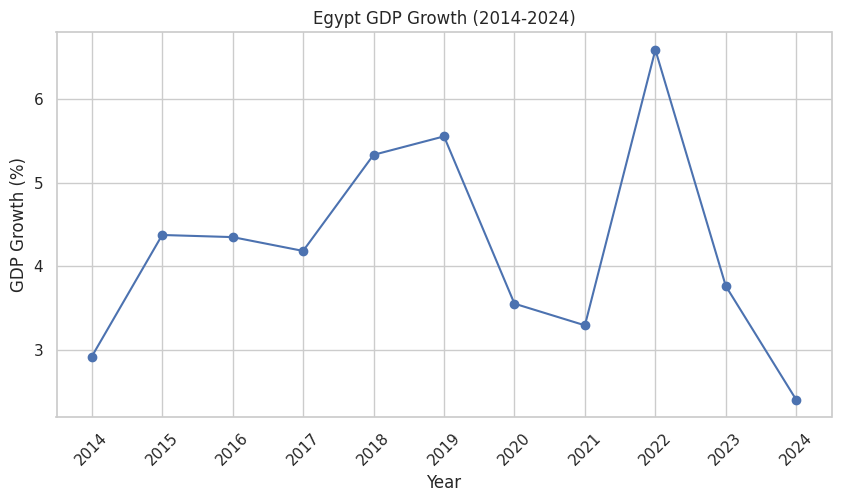

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(df.index, df["GDP_Growth"], marker="o")

plt.title("Egypt GDP Growth (2014-2024)")
plt.xlabel("Year")
plt.ylabel("GDP Growth (%)")

plt.xticks(df.index, rotation=45)

plt.show()

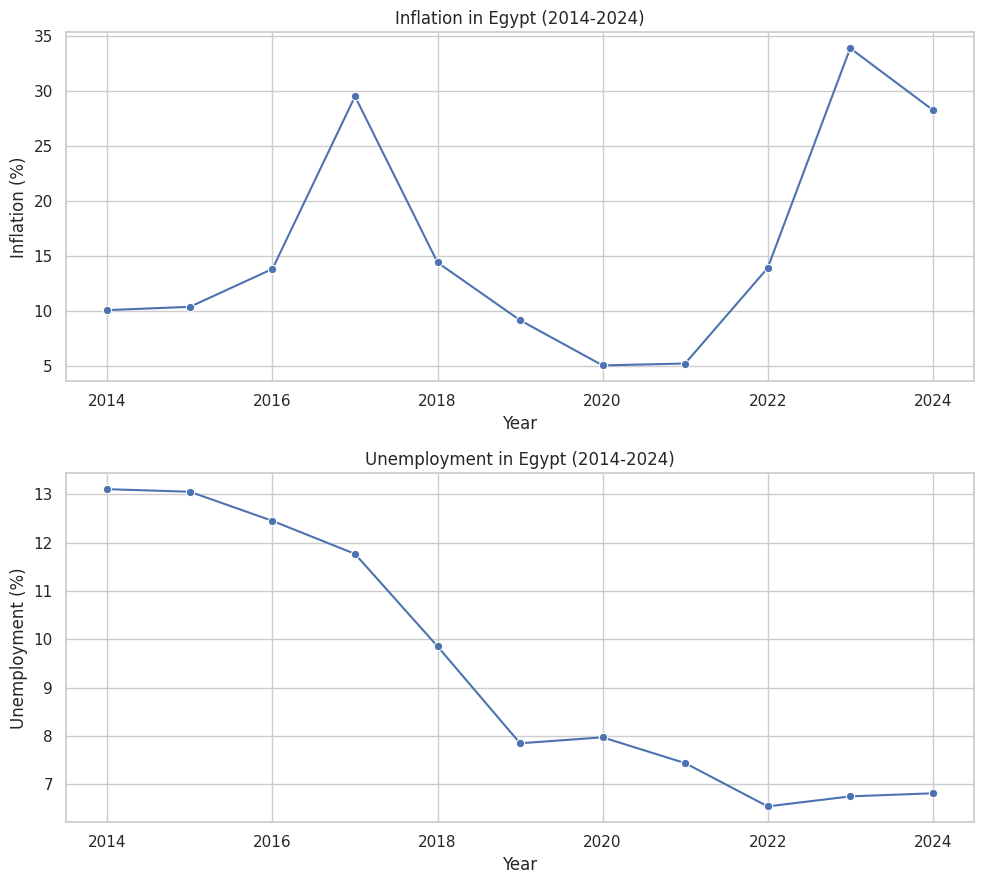

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9))

sns.lineplot(
    x=df.index,
    y=df["Inflation"],
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Inflation in Egypt (2014-2024)")
axes[0].set_ylabel("Inflation (%)")

sns.lineplot(
    x=df.index,
    y=df["Unemployment"],
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Unemployment in Egypt (2014-2024)")
axes[1].set_ylabel("Unemployment (%)")

plt.tight_layout()
plt.show()

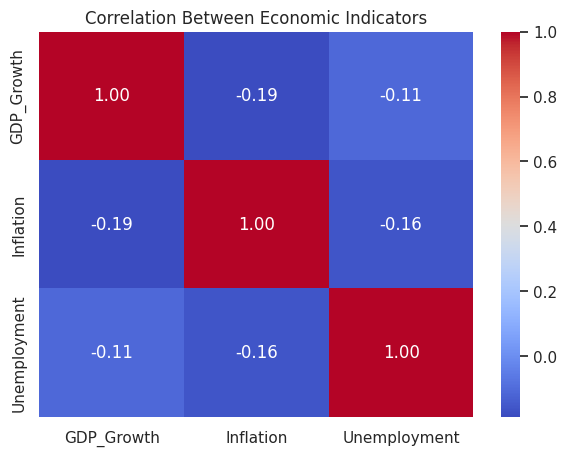

In [20]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Economic Indicators")

plt.show()

In [21]:
# 1. تحديد السنوات ذات القيم الأعلى والأقل
highest_inflation_year = df["Inflation"].idxmax()
lowest_growth_year = df["GDP_Growth"].idxmin()
highest_growth_year = df["GDP_Growth"].idxmax()

# 2. الطباعة بأسلوب آمن يتفادى القيم الفارغة (NaN)
highest_inf_val = df.loc[highest_inflation_year, "Inflation"]
lowest_growth_val = df.loc[lowest_growth_year, "GDP_Growth"]
highest_growth_val = df.loc[highest_growth_year, "GDP_Growth"]

print(
    f"Highest inflation was recorded in {highest_inflation_year}: {highest_inf_val:.2f}%"
)
print(
    f"Lowest GDP growth was recorded in {lowest_growth_year}: {lowest_growth_val:.2f}%"
)
print(
    f"Highest GDP growth was recorded in {highest_growth_year}: {highest_growth_val:.2f}%"
)

print("\nCorrelation Matrix:")
display(df.corr())

Highest inflation was recorded in 2023: 33.88%
Lowest GDP growth was recorded in 2024: 2.40%
Highest GDP growth was recorded in 2022: 6.59%

Correlation Matrix:


,GDP_Growth,Inflation,Unemployment
GDP_Growth,1.000000,-0.185557,-0.108618
Inflation,-0.185557,1.000000,-0.160979
Unemployment,-0.108618,-0.160979,1.000000


In [22]:
df.to_csv("Egypt_Economic_Indicators_Cleaned.csv")

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
